# Permanente evaluatie - vaardigheidstoets 2
16 november - 2ITAI - AP Hogeschool

## Opgave

Laad de volgende dataset in: de wine dataset via `from sklearn.datasets import load_wine` - deze dataset bevat informatie over wijnen, en 3 labels (class 0, class 1, class 2, hier is verder niets over gekend). Die labels hebben ze helemaal op het eind kort nodig.

Pas op deze dataset een datareductietechniek toe, en cluster vervolgens de gereduceerde dataset zo goed mogelijk. Zorg voor preprocessing waar nodig, en zoek naar een optimaal model. **Indien je bepaalde keuzes maakt, schrijf kort in de notebook waarom**. Vergelijk op het einde of de labels van je clusteringalgoritme overeenkomen met de originele labels `wine.target`, met behulp van een confusion matrix waarbij je de labels meegeeft en de clusters (clusters zijn het resultaat van `fit_predict()`). Trek hier conclusies uit en noteer deze in de notebook.

### Inleveren:
- Hernoem je bestand naar **PE2-VoornaamNaam.ipynb** waarbij je je *eigen naam* invult.
- Laadt dit bestand op naar de uploadzone op toets.ap.be voor het einde van deze test.

Jullie krijgen **60 minuten** de tijd.

### Indicatieve puntenverdeling /20
- goede algoritmes: 2 keer 4 ptn
- goede beschrijving over keuze van deze algoritmes: 4 ptn
- overige noodzakelijke stappen: 8 ptn
- Hierna wordt er gekeken naar code stijl

## Meer info over de dataset
Te verkrijgen via 
```python
wine = load_wine()
print(wine.DESCR)
```

# Oplossing

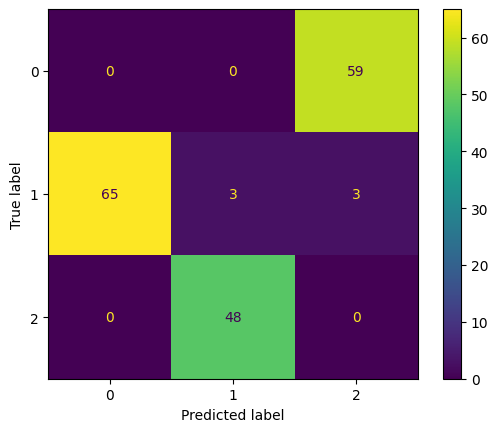

In [ ]:
# Code
import pandas as pd
import numpy as np
from sklearn import datasets
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

wine = datasets.load_wine()
data = wine.data

scaler = StandardScaler()
data_scaled = scaler.fit_transform(data)

pca = PCA(n_components=0.95)
X_pca = pca.fit_transform(data_scaled)

k_range = list(range(2, 8))
sil_scores = []
best_sil = -1
best_k = None

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_pca)

    sil_score = silhouette_score(data_scaled, kmeans.labels_)
    sil_scores.append(sil_score)

    if sil_score > best_sil:
        best_sil = sil_score
        best_k = k

clusters = KMeans(n_clusters=best_k, random_state=42, n_init=10).fit_predict(X_pca)

cm = confusion_matrix(wine.target, clusters)
disp  = ConfusionMatrixDisplay(confusion_matrix=cm)

disp.plot()

Ik koos voor Kmeans omdat de data bolvormig is in de wine dataset.

Ik ga over verschillende k's om een hogere nauwkeurigheid te bekomen.

Er is iets raar aan de hand want het algoritme labelt bijna alles met label 0 label 2, alles met label 1 label 0 en bijna alles met label 2 label 1.

Maar je ziet wel dat hij ook al heeft hij de labels fout dat het nog een goed onderscheid kan houden tussen de verschillende soorten wijn.